# Breast Cancer Prediction System
### AIML Practical No. 10: AI/ML-Based Real-World Application (Disease Prediction)

**Group members:** Sanket Kandalkar (TEITA30), Karan Jagtap (TEITA31), Chinmay Jadhav (TEITA27)
---

## 1. Problem Statement
Breast cancer is one of the most common cancers worldwide, and early detection greatly improves the chances of successful treatment. A fine-needle aspiration (FNA) biopsy produces digitised images of cell nuclei, from which measurable features such as radius, texture and smoothness are computed. Manually interpreting these measurements is slow and subjective.

**Goal:** build a machine learning system that predicts whether a tumour is **malignant (cancerous)** or **benign (non-cancerous)** from these cell-nucleus measurements.

## 2. Objectives
1. Select and understand a real-world medical dataset.
2. Clean, explore (EDA) and preprocess the data.
3. Select the most informative features.
4. Train and compare several ML models.
5. Tune the best models with cross-validated hyperparameter search.
6. Evaluate using medically meaningful metrics (recall, precision, F1, ROC-AUC).
7. Save the final model and demonstrate predictions on new patient data.

> **Why recall matters:** in disease prediction, a *false negative* (missing a cancer case) is far more costly than a *false positive*. We therefore pay special attention to **recall** for the malignant class.

## 3. Import Libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)
os.makedirs("models", exist_ok=True)

## 4. Dataset Collection / Selection
We use the **Breast Cancer Wisconsin (Diagnostic) dataset** (UCI Machine Learning Repository), which ships with scikit-learn, so no download is needed.

- **569 samples**, **30 numeric features**, no missing values
- For each cell nucleus, 10 properties are measured (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension). For each, the **mean**, **standard error** and **worst** (largest) value are recorded, giving 30 features.
- **Target:** malignant or benign. In the original data 0 = malignant and 1 = benign. We flip this so that **1 = malignant (disease present)**, which makes "positive class" = "has the disease" and makes recall easier to interpret.

In [2]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()

# Flip target so that 1 = malignant (disease), 0 = benign
df["target"] = 1 - df["target"]
df["diagnosis"] = df["target"].map({1: "Malignant", 0: "Benign"})

print("Shape:", df.shape)
df.head()

Shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1,Malignant


## 5. Data Preprocessing and Exploratory Data Analysis (EDA)

### 5.1 Data quality checks

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()
df.info()

Missing values: 0
Duplicate rows: 0

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  

In [4]:
df.drop(columns=["diagnosis"]).describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


### 5.2 Class distribution

diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
diagnosis
Benign       62.7 %
Malignant    37.3 %
Name: count, dtype: str


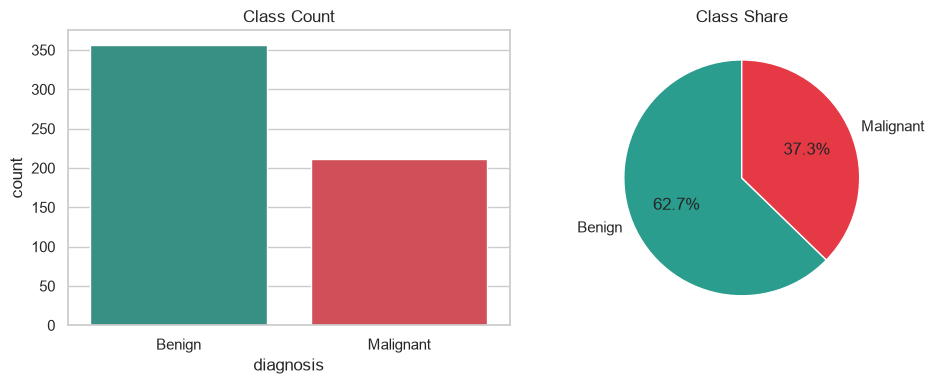

In [5]:
counts = df["diagnosis"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="diagnosis", palette=["#2a9d8f", "#e63946"], order=["Benign", "Malignant"], ax=ax[0])
ax[0].set_title("Class Count")
ax[1].pie(counts[["Benign", "Malignant"]], labels=["Benign", "Malignant"], autopct="%1.1f%%",
          colors=["#2a9d8f", "#e63946"], startangle=90)
ax[1].set_title("Class Share")
plt.tight_layout()
plt.savefig("images/01_class_distribution.png", dpi=150)
plt.show()

The dataset is moderately imbalanced (about 63% benign, 37% malignant). We will use **stratified** splits so both train and test sets keep the same ratio.

### 5.3 Feature distributions by class

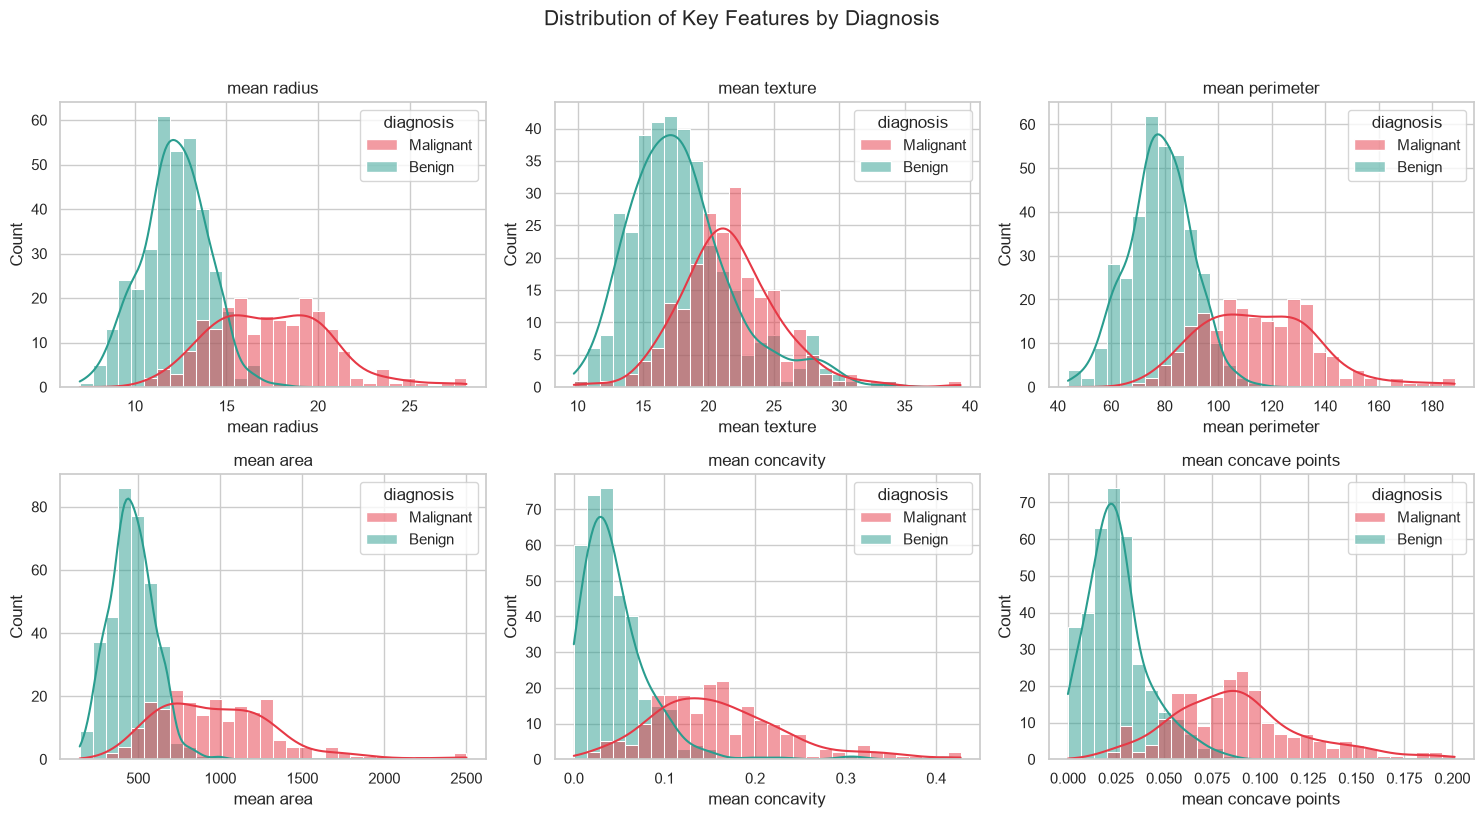

In [6]:
key_features = ["mean radius", "mean texture", "mean perimeter",
                "mean area", "mean concavity", "mean concave points"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), key_features):
    sns.histplot(data=df, x=feat, hue="diagnosis", kde=True, bins=30,
                 palette={"Benign": "#2a9d8f", "Malignant": "#e63946"}, ax=ax)
    ax.set_title(feat)
plt.suptitle("Distribution of Key Features by Diagnosis", fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig("images/02_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

Malignant tumours generally have noticeably larger radius, perimeter, area, concavity and concave points. These features clearly separate the two classes, which suggests the problem is well suited for ML.

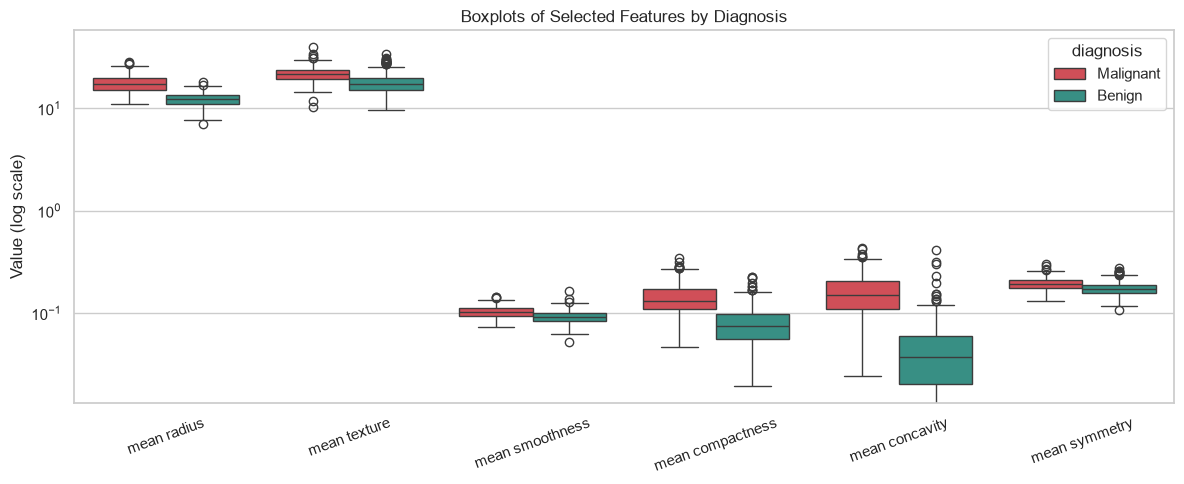

In [7]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df.melt(id_vars="diagnosis", value_vars=["mean radius", "mean texture", "mean smoothness",
                                                         "mean compactness", "mean concavity", "mean symmetry"]),
            x="variable", y="value", hue="diagnosis",
            palette={"Benign": "#2a9d8f", "Malignant": "#e63946"})
plt.yscale("log")
plt.xlabel("")
plt.ylabel("Value (log scale)")
plt.title("Boxplots of Selected Features by Diagnosis")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("images/03_boxplots.png", dpi=150)
plt.show()

### 5.4 Correlation analysis

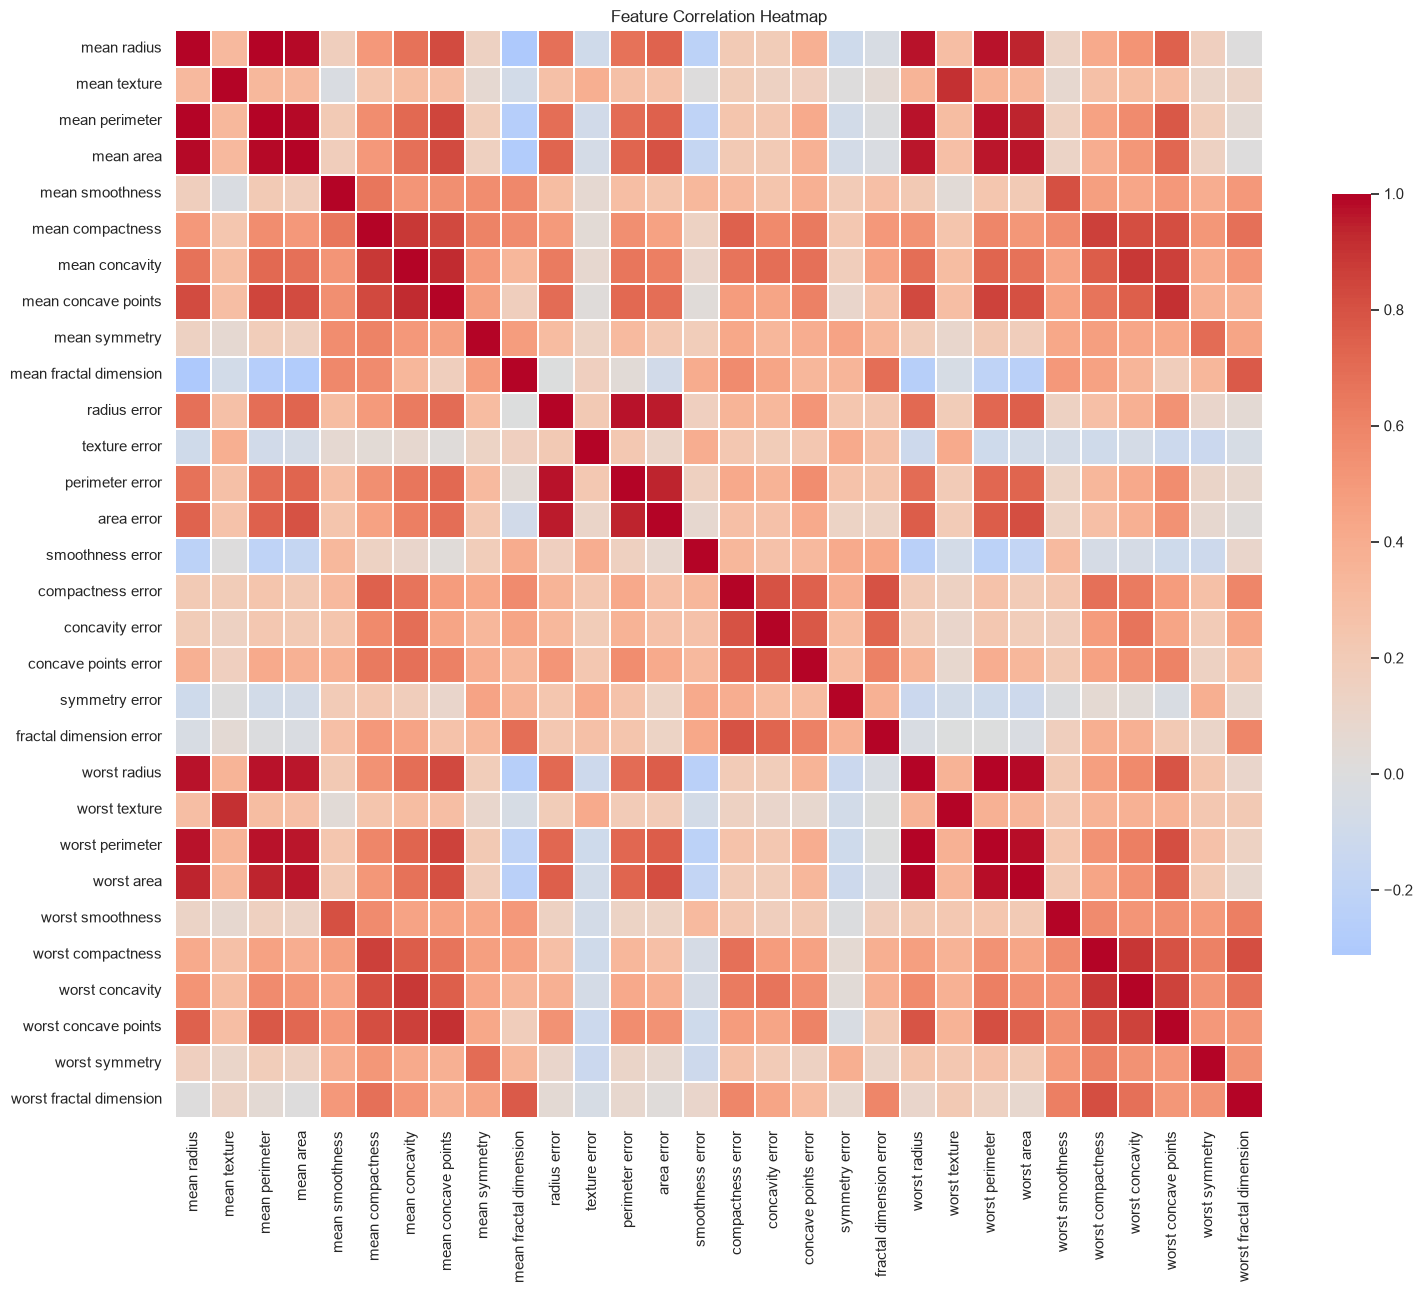

In [8]:
features = [c for c in df.columns if c not in ("target", "diagnosis")]

corr = df[features].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, linewidths=0.2, cbar_kws={"shrink": 0.7})
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("images/04_correlation_heatmap.png", dpi=150)
plt.show()

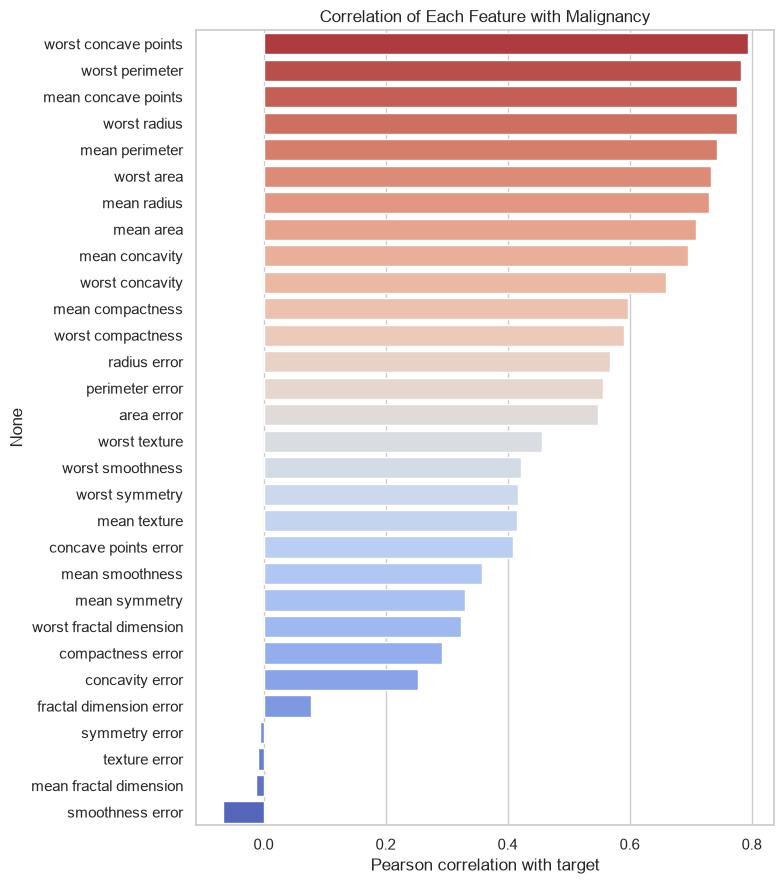

Top 5 positively correlated features:
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
dtype: float64


In [9]:
target_corr = df[features].corrwith(df["target"]).sort_values(ascending=False)

plt.figure(figsize=(8, 9))
sns.barplot(x=target_corr.values, y=target_corr.index, palette="coolwarm_r")
plt.title("Correlation of Each Feature with Malignancy")
plt.xlabel("Pearson correlation with target")
plt.tight_layout()
plt.savefig("images/05_target_correlation.png", dpi=150)
plt.show()

print("Top 5 positively correlated features:")
print(target_corr.head(5).round(3))

Many features (radius, perimeter, area) are almost perfectly correlated with each other. This **multicollinearity** is something to keep in mind: it can hurt linear models, while tree-based models handle it more gracefully.

### 5.5 Outlier check

In [10]:
Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((df[features] < (Q1 - 1.5 * IQR)) | (df[features] > (Q3 + 1.5 * IQR))).sum()
print("Features with the most IQR outliers:")
print(outlier_counts.sort_values(ascending=False).head(8))

Features with the most IQR outliers:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
dtype: int64


Outliers exist, but they correspond to genuine large tumours rather than data-entry errors. Since removing them would delete exactly the malignant cases we want to detect, we **keep them** and rely on scaling and robust models.

### 5.6 Train / test split and scaling

We split the data **80% train / 20% test** with stratification. Scaling is placed **inside a Pipeline** so that the scaler is fitted only on training folds. This prevents *data leakage* from the test set.

In [11]:
X = df[features]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant share in train: %.1f%%" % (y_train.mean() * 100))
print("Malignant share in test : %.1f%%" % (y_test.mean() * 100))

Train: (455, 30)  Test: (114, 30)
Malignant share in train: 37.4%
Malignant share in test : 36.8%


## 6. Feature Selection / Engineering

We use two complementary approaches:
1. **Univariate selection (ANOVA F-test)** to rank features by how strongly each one separates the classes.
2. **Removal of near-duplicate features** (correlation > 0.95) to reduce redundancy.

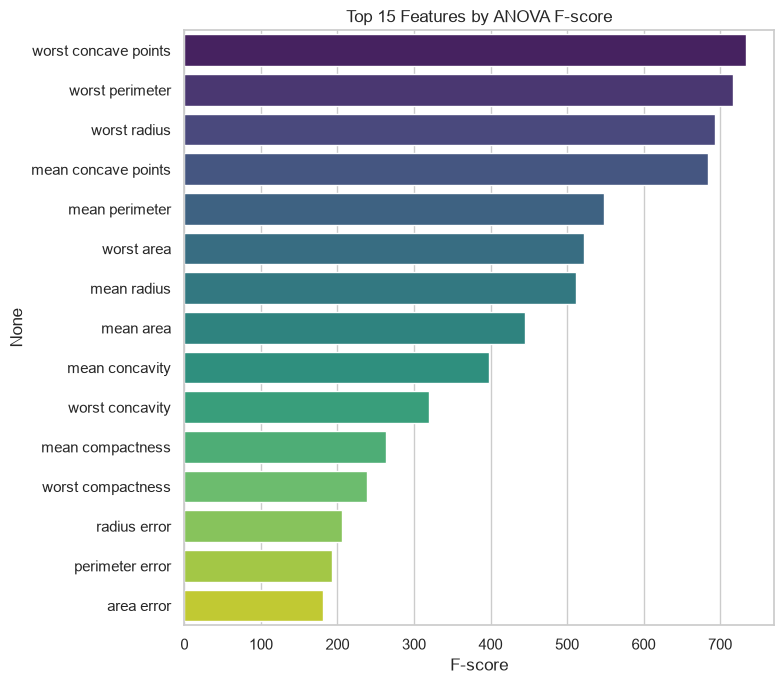

In [12]:
selector = SelectKBest(score_func=f_classif, k="all").fit(X_train, y_train)
scores = pd.Series(selector.scores_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 7))
sns.barplot(x=scores.head(15).values, y=scores.head(15).index, palette="viridis")
plt.title("Top 15 Features by ANOVA F-score")
plt.xlabel("F-score")
plt.tight_layout()
plt.savefig("images/06_feature_scores.png", dpi=150)
plt.show()

In [13]:
df.to_csv("full_dataset.csv")


In [14]:
# Engineered features: simple ratios that can capture tumour shape
def add_features(data):
    out = data.copy()
    out["area_to_perimeter"] = out["mean area"] / out["mean perimeter"]
    out["worst_to_mean_radius"] = out["worst radius"] / out["mean radius"]
    out["concavity_x_points"] = out["mean concavity"] * out["mean concave points"]
    return out

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
print("Features after engineering:", X_train_fe.shape[1])

Features after engineering: 33


In [15]:
# Drop one feature from each highly correlated pair (|r| > 0.95), keeping the one
# with the higher F-score
all_scores = pd.Series(
    SelectKBest(f_classif, k="all").fit(X_train_fe, y_train).scores_, index=X_train_fe.columns
)
corr_m = X_train_fe.corr().abs()
to_drop = set()
for col in all_scores.sort_values(ascending=False).index:
    if col in to_drop:
        continue
    for other in corr_m.columns:
        if other != col and other not in to_drop and corr_m.loc[col, other] > 0.95:
            to_drop.add(other)

selected_features = [c for c in X_train_fe.columns if c not in to_drop]
print(f"Dropped {len(to_drop)} redundant features, kept {len(selected_features)}:")
print(selected_features)

X_train_sel = X_train_fe[selected_features]
X_test_sel = X_test_fe[selected_features]

Dropped 8 redundant features, kept 25:
['mean texture', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'worst_to_mean_radius', 'concavity_x_points']


## 7. Selection and Implementation of ML Models

We compare five classic classifiers:

| Model | Why it is included |
|---|---|
| Logistic Regression | Simple, interpretable baseline |
| K-Nearest Neighbours | Instance-based, no training assumptions |
| Support Vector Machine (RBF) | Strong on small, high-dimensional, scaled data |
| Random Forest | Robust ensemble, handles correlated features |
| Gradient Boosting | Powerful boosting ensemble |

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

def make_pipe(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

pipelines = {name: make_pipe(m) for name, m in models.items()}

## 8. Model Training and Testing

### 8.1 5-fold stratified cross-validation (training data only)

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_rows = []
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X_train_sel, y_train, cv=cv, scoring=scoring)
    cv_rows.append({"Model": name, **{m.capitalize(): res[f"test_{m}"].mean() for m in scoring}})

cv_results = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_results.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,Roc_auc
Model,,,,,
Logistic Regression,0.9714,0.9886,0.9353,0.9605,0.9956
Gradient Boosting,0.9670,0.9763,0.9353,0.9547,0.9893
Random Forest,0.9670,0.9758,0.9353,0.9547,0.9903
SVM (RBF),0.9560,0.9694,0.9118,0.9387,0.9946
KNN,0.9560,0.9931,0.8882,0.9372,0.9872


### 8.2 Fit on the full training set and test on unseen data

In [18]:
test_rows, fitted = [], {}
for name, pipe in pipelines.items():
    pipe.fit(X_train_sel, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test_sel)
    proba = pipe.predict_proba(X_test_sel)[:, 1]
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

test_results = pd.DataFrame(test_rows).set_index("Model").round(4)
test_results.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
SVM (RBF),0.9737,1.000,0.9286,0.9630,0.9957
Gradient Boosting,0.9737,1.000,0.9286,0.9630,0.9990
Logistic Regression,0.9649,0.975,0.9286,0.9512,0.9957
Random Forest,0.9649,1.000,0.9048,0.9500,0.9993
KNN,0.9386,0.973,0.8571,0.9114,0.9679


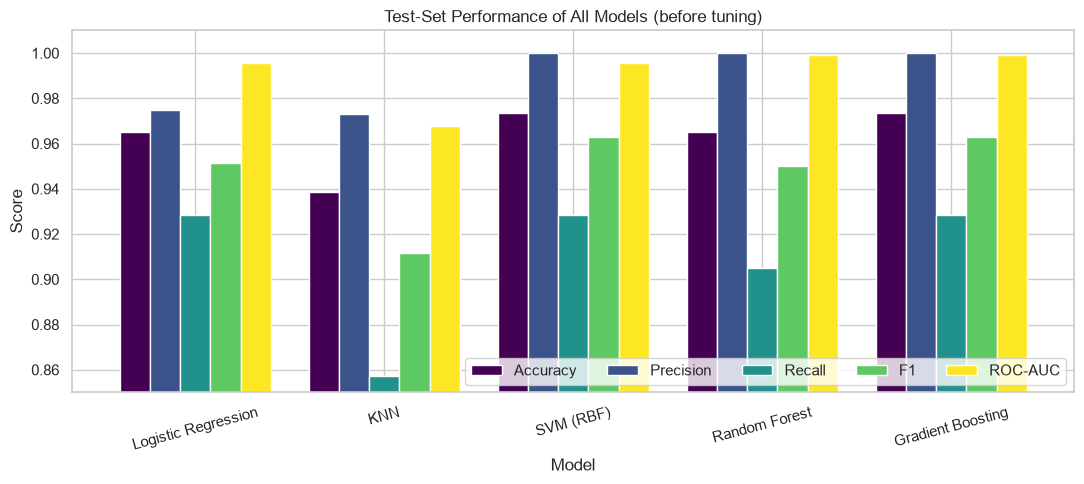

In [19]:
ax = test_results.plot(kind="bar", figsize=(11, 5), colormap="viridis", width=0.8)
plt.title("Test-Set Performance of All Models (before tuning)")
plt.ylabel("Score")
plt.ylim(0.85, 1.01)
plt.xticks(rotation=15)
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.savefig("images/07_model_comparison.png", dpi=150)
plt.show()

### 8.3 Hyperparameter tuning (GridSearchCV)

We tune the SVM and Random Forest with a grid search, refitting on the best **F1** (the balance of precision and recall). Recall is tracked during the search as well.

In [20]:
param_grids = {
    "SVM (RBF)": {
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.001],
    },
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
    },
}

tuned = {}
for name, grid in param_grids.items():
    gs = GridSearchCV(pipelines[name], grid, cv=cv, scoring=["recall", "f1"],
                      refit="f1", n_jobs=-1)
    gs.fit(X_train_sel, y_train)
    tuned[name] = gs
    print(f"{name}\n  best params : {gs.best_params_}\n  CV F1       : {gs.best_score_:.4f}\n")

SVM (RBF)
  best params : {'model__C': 10, 'model__gamma': 0.01}
  CV F1       : 0.9630

Random Forest
  best params : {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
  CV F1       : 0.9577



## 9. Performance Evaluation

In [21]:
final_rows = []
final_models = {"Logistic Regression": fitted["Logistic Regression"],
                "KNN": fitted["KNN"],
                "Gradient Boosting": fitted["Gradient Boosting"],
                "SVM (tuned)": tuned["SVM (RBF)"].best_estimator_,
                "Random Forest (tuned)": tuned["Random Forest"].best_estimator_}

for name, model in final_models.items():
    pred = model.predict(X_test_sel)
    proba = model.predict_proba(X_test_sel)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    cv_f1 = cross_validate(model, X_train_sel, y_train, cv=cv, scoring="f1")["test_score"].mean()
    final_rows.append({
        "Model": name,
        "CV F1 (train)": cv_f1,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "False Negatives": fn,
        "False Positives": fp,
    })

final_results = pd.DataFrame(final_rows).set_index("Model").round(4)
final_results.sort_values("CV F1 (train)", ascending=False)

,CV F1 (train),Accuracy,Precision,Recall,F1,ROC-AUC,False Negatives,False Positives
Model,,,,,,,,
SVM (tuned),0.9630,0.9737,1.000,0.9286,0.9630,0.9980,3,0
Logistic Regression,0.9605,0.9649,0.975,0.9286,0.9512,0.9957,3,1
Random Forest (tuned),0.9577,0.9649,1.000,0.9048,0.9500,0.9990,4,0
Gradient Boosting,0.9547,0.9737,1.000,0.9286,0.9630,0.9990,3,0
KNN,0.9372,0.9386,0.973,0.8571,0.9114,0.9679,6,1


**Model selection rule:** the final model is chosen using the **cross-validated F1 on the training data**, *not* the test score. Choosing by test score would leak information from the test set into our decision and make the reported result over-optimistic. The test set is used only to report how the chosen model performs on unseen data.

In [22]:
best_name = final_results.sort_values("CV F1 (train)", ascending=False).index[0]
best_model = final_models[best_name]
print("Selected final model:", best_name)

pred = best_model.predict(X_test_sel)
print()
print(classification_report(y_test, pred, target_names=["Benign", "Malignant"], digits=4))

Selected final model: SVM (tuned)

              precision    recall  f1-score   support

      Benign     0.9600    1.0000    0.9796        72
   Malignant     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



### Confusion matrix and ROC curves

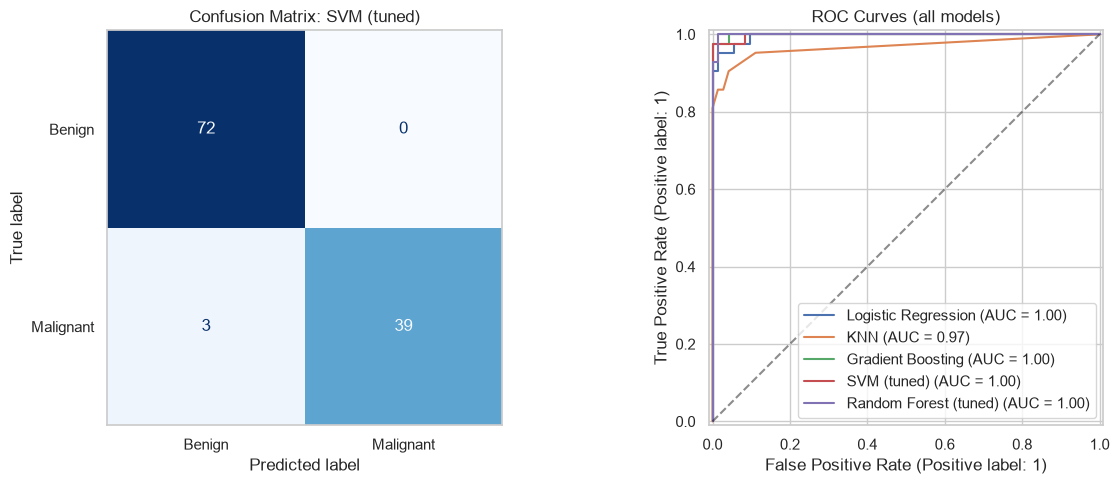

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Benign", "Malignant"], cmap="Blues", ax=ax[0], colorbar=False
)
ax[0].set_title(f"Confusion Matrix: {best_name}")
ax[0].grid(False)

for name, model in final_models.items():
    RocCurveDisplay.from_estimator(model, X_test_sel, y_test, name=name, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_title("ROC Curves (all models)")

plt.tight_layout()
plt.savefig("images/08_confusion_roc.png", dpi=150)
plt.show()

**Reading the confusion matrix:**
- *True Negatives*: benign tumours correctly identified
- *True Positives*: malignant tumours correctly caught
- *False Negatives*: malignant tumours **missed** (the most dangerous error)
- *False Positives*: benign tumours wrongly flagged (leads to extra tests, but is far less harmful)

## 10. Results and Visualization

### 10.1 Which features drive the prediction?

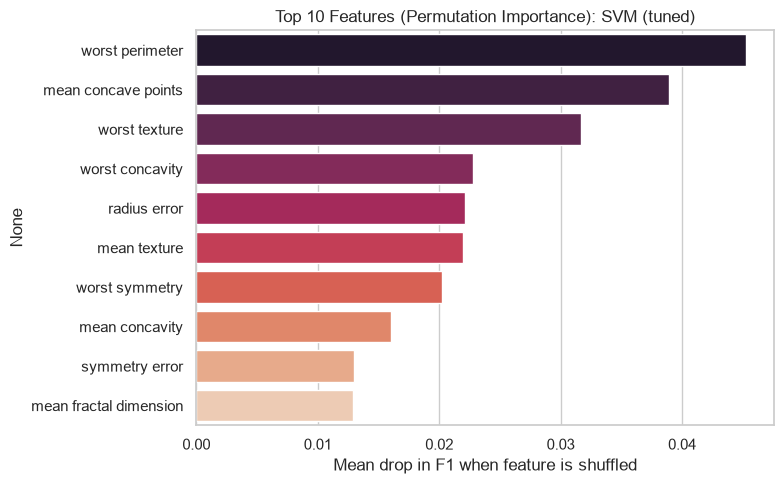

In [24]:
perm = permutation_importance(best_model, X_test_sel, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="f1")
imp = pd.Series(perm.importances_mean, index=selected_features).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, palette="rocket")
plt.title(f"Top 10 Features (Permutation Importance): {best_name}")
plt.xlabel("Mean drop in F1 when feature is shuffled")
plt.tight_layout()
plt.savefig("images/09_permutation_importance.png", dpi=150)
plt.show()

### 10.2 Cross-validated stability of the final model

In [25]:
# Re-run CV on the full pipeline (feature engineering applied first) for a fair estimate
full_X = add_features(X)[selected_features]
cv_final = cross_validate(best_model, full_X, y, cv=cv, scoring=scoring)
summary = pd.DataFrame({m: [cv_final[f"test_{m}"].mean(), cv_final[f"test_{m}"].std()] for m in scoring},
                       index=["mean", "std"]).T.round(4)
summary

,mean,std
accuracy,0.9771,0.0205
precision,0.9902,0.0195
recall,0.9481,0.0432
f1,0.9683,0.0281
roc_auc,0.9961,0.0054


## 11. Save the Model and Make Predictions

In [26]:
joblib.dump({"model": best_model, "features": selected_features}, "models/breast_cancer_model.joblib")
print("Model saved to models/breast_cancer_model.joblib")

def predict_patient(patient_row):
    """patient_row: a pandas Series or dict with the 30 original measurements."""
    bundle = joblib.load("models/breast_cancer_model.joblib")
    row = pd.DataFrame([patient_row])[features]
    row = add_features(row)[bundle["features"]]
    prob = bundle["model"].predict_proba(row)[0, 1]
    label = "Malignant" if prob >= 0.5 else "Benign"
    return label, prob

# Demo on 5 unseen test patients
for idx in X_test.index[:5]:
    label, prob = predict_patient(X_test.loc[idx])
    actual = "Malignant" if y_test.loc[idx] == 1 else "Benign"
    print(f"Patient #{idx:<4} predicted: {label:<10} (P(malignant) = {prob:.3f})   actual: {actual}")

Model saved to models/breast_cancer_model.joblib
Patient #120  predicted: Benign     (P(malignant) = 0.001)   actual: Benign
Patient #250  predicted: Malignant  (P(malignant) = 1.000)   actual: Malignant
Patient #375  predicted: Benign     (P(malignant) = 0.012)   actual: Benign
Patient #99   predicted: Benign     (P(malignant) = 0.233)   actual: Malignant
Patient #455  predicted: Benign     (P(malignant) = 0.186)   actual: Benign


## 12. Conclusion

In [27]:
best_row = final_results.loc[best_name]
print(f"Final model          : {best_name}")
print(f"Accuracy             : {best_row['Accuracy']:.2%}")
print(f"Recall (malignant)   : {best_row['Recall']:.2%}")
print(f"Precision            : {best_row['Precision']:.2%}")
print(f"ROC-AUC              : {best_row['ROC-AUC']:.4f}")
print(f"Missed cancers (FN)  : {int(best_row['False Negatives'])} out of {int(y_test.sum())} malignant cases in the test set")

Final model          : SVM (tuned)
Accuracy             : 97.37%
Recall (malignant)   : 92.86%
Precision            : 100.00%
ROC-AUC              : 0.9980
Missed cancers (FN)  : 3 out of 42 malignant cases in the test set


**Summary**
- We built an end-to-end pipeline for predicting breast cancer from cell-nucleus measurements: EDA, preprocessing, feature engineering and selection, model comparison, hyperparameter tuning and evaluation.
- Several models reach very high accuracy, and the dataset's malignant/benign classes are strongly separable on features such as radius, perimeter, area, concavity and concave points.
- Placing scaling inside a Pipeline and using stratified cross-validation avoids data leakage and gives honest performance estimates.

**Limitations**
- The dataset is small (569 patients) and comes from a single source, so results may not generalise to other hospitals or imaging equipment.
- The model supports, but must never replace, a clinician's judgement.

**Future work**
- Validate on external datasets, try probability calibration and threshold tuning to push recall even higher, and explore explainability tools such as SHAP.
- Wrap the model in a simple web app (Streamlit/Flask) for interactive predictions.